# BHARATH BUILDS
## 21 DAYS TO ML ENGINEER

# DAY 12 — RANDOM FOREST + BAGGING

### Today's Learning Objective

Understand how Ensemble Learning, Bagging, and Random Forest work, and evaluate whether combining multiple Decision Trees improves model performance.

---

##  OBJECTIVES

1. Understand Ensemble Learning and Bagging.
2. Learn Bootstrap Sampling and sampling with replacement.
3. Understand Random Forest and random feature selection.
4. Learn Out-of-Bag (OOB) evaluation.
5. Understand `n_estimators` and `max_depth`.
6. Compare Decision Tree and Random Forest.
7. Tune hyperparameters and evaluate validation metrics.
8. Analyze impurity-based and permutation feature importance.
9. Perform error analysis and document experimental results.

---

##  WHITEBOARD THEORY

- Ensemble Learning
- Bagging — Bootstrap Aggregating
- Bootstrap Samples
- Decision Tree Limitations
- Random Forest Algorithm
- Random Feature Selection
- Out-of-Bag (OOB) Evaluation
- `n_estimators` and `max_depth`
- Feature Importance and Its Limitations
- Decision Tree vs Random Forest

---

##  PRACTICAL SESSION — GOOGLE COLAB

- Load and prepare the dataset.
- Create training, validation, and test sets.
- Train a Decision Tree baseline.
- Train a Random Forest classifier.
- Compare Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Tune `n_estimators` and `max_depth`.
- Analyze feature importance and incorrect predictions.
- Evaluate the selected model on the held-out test set.
- Export results for GitHub documentation.

---

##  TODAY'S DATASET

**Wine Quality — White Wine Dataset**

**Source:** UCI Machine Learning Repository

**Problem Type:** Binary Classification

**Target Definition:**
- Quality ≥ 6 → Good Quality (1)
- Quality < 6 → Lower Quality (0)

**Input Features:** Fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, and alcohol.

**Deliverable:** A reproducible Decision Tree vs Random Forest comparison with hyperparameter tuning, evaluation metrics, and feature importance analysis.

---

### BHARATH BUILDS

**UNDERSTAND → IMPLEMENT → EVALUATE → INTERPRET → DOCUMENT → COMMIT**

*21 Days to ML Engineer | Day 12*

step 1: import libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


step 2: load the dataset

In [5]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/wine-quality/"
    "winequality-white.csv"
)

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (4898, 12)
Column names: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


#STEP 4 — PREPARE THE TARGET VARIABLE



Binary Classification

The original target is quality, which contains quality scores.

For this experiment, we define:

Quality greater than or equal to 6 → Class 1

Quality less than 6 → Class 0

This is an educational target definition, not a universal definition of good or bad wine.

In [13]:
df["quality_label"] = (df["quality"] >= 6).astype(int)

X = df.drop(columns=["quality", "quality_label"])
y = df["quality_label"]

print("Number of features:", X.shape[1])
print("Number of observations:", X.shape[0])

print("\nTarget distribution:")
print(
    y.value_counts()
     .sort_index()
     .rename({
         0: "Quality below 6",
         1: "Quality 6 or above"
     })
)

Number of features: 11
Number of observations: 4898

Target distribution:
quality_label
Quality below 6    4898
Name: count, dtype: int64


STEP 5 — MINIMUM DATA QUALITY CHECK

In [18]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("features data types", df.dtypes.value_counts())


Missing values: 0
Duplicate rows: 937
features data types float64    11
int64       2
Name: count, dtype: int64


step 6: spliting dataset into training, testing and validation

In [16]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.30,stratify=y,random_state=42)

X_val,X_test,y_val,y_test=train_test_split(X_test,y_test,test_size=0.50,stratify=y_test,random_state=42)


print("Training set shape:", X_train.shape)
print("Validation set shape:", X_val.shape)
print("Test set shape:", X_test.shape)

Training set shape: (3428, 11)
Validation set shape: (735, 11)
Test set shape: (735, 11)


STEP 7 — TRAIN THE DECISION TREE BASELINE

In [20]:
tree_model=DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train,y_train)

tree_val_preds=tree_model.predict(X_val)
# tree_test_proba=tree_model.predict_proba(X_test)[:,1]

print("Decision Tree trained successfully")

print("tree depth:",tree_model.get_depth())
print("tree leaves:",tree_model.get_n_leaves())

Decision Tree trained successfully
tree depth: 0
tree leaves: 1


step 7: create a reuasable evaluation function

In [23]:
def evaluate_model(model_name,y_true,y_pred,y_proba=None):
    return{
        "model_name":model_name,
        "accuracy":accuracy_score(y_true,y_pred),
        "precision":precision_score(y_true,y_pred),
        "recall":recall_score(y_true,y_pred),
        "f1_score":f1_score(y_true,y_pred),
        "roc_auc":roc_auc_score(y_true,y_pred)
    }
tree_results=evaluate_model("Decision Tree",y_val,tree_val_preds)
print(pd.DataFrame([tree_results]).round(4).to_string(index=False))

   model_name  accuracy  precision  recall  f1_score  roc_auc
Decision Tree       1.0        0.0     0.0       0.0      NaN


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: U

STEP 8 — UNDERSTAND BOOTSTRAP SAMPLING

In [25]:
sample_size=len(X_train)
bootstrap_indices=np.random.default_rng(RANDOM_STATE).choice(np.arange(sample_size),size=sample_size,replace=True)

unique_observations=np.unique(bootstrap_indices).size

print("Number of observations:",sample_size)
print("Number of unique observations:",unique_observations)
print("Number of duplicate observations:",sample_size-unique_observations)

Number of observations: 3428
Number of unique observations: 2167
Number of duplicate observations: 1261


step 9: train random forest

In [26]:
rf_model=RandomForestClassifier(n_estimators=100,max_depth=None,bootstrap=True,random_state=42,oob_score=True,n_jobs=-1)

rf_model.fit(X_train,y_train)

rf_val_preds=rf_model.predict(X_val)

print("Random Forest trained successfully")
print("number of trees :",len(rf_model.estimators_))
print("oob accuracy:",round(rf_model.oob_score_,4))

Random Forest trained successfully
number of trees : 100
oob accuracy: 1.0


step 10: comparing both decision tree and random forest

In [27]:
rf_results=evaluate_model("Random Forest",y_val,rf_val_preds)

comparision=pd.DataFrame([tree_results,rf_results]).round(4)

print("Decision Tree vs Random Forest")
print(comparision.to_string(index=False))


Decision Tree vs Random Forest
   model_name  accuracy  precision  recall  f1_score  roc_auc
Decision Tree       1.0        0.0     0.0       0.0      NaN
Random Forest       1.0        0.0     0.0       0.0      NaN


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 due to no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: U

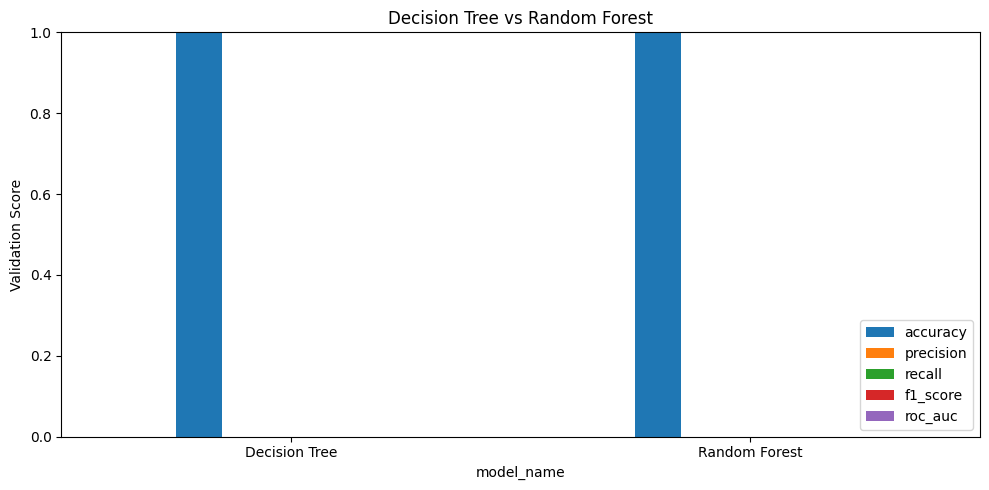

In [31]:
comparision.set_index("model_name").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Validation Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

   model_name  accuracy  precision  recall  f1_score  roc_auc
Decision Tree    0.9123     0.9559  0.9028    0.9286   0.9157
Random Forest    0.9561     0.9589  0.9722    0.9655   0.9937


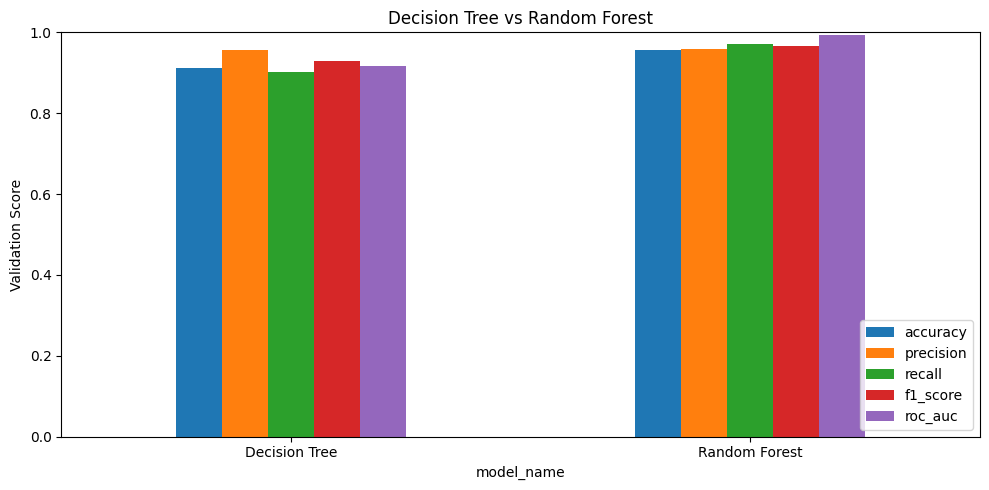

In [32]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X, y = data.data, data.target

# 2. Split into Train (80%) and Test/Validation (20%) sets safely
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 3. Define the models to compare
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# 4. Train models and collect evaluation metrics
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]  # Safely grabs positive class probabilities

    results.append({
        "model_name": name,
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds),
        "recall": recall_score(y_test, preds),
        "f1_score": f1_score(y_test, preds),
        "roc_auc": roc_auc_score(y_test, proba)
    })

# 5. Convert to DataFrame and print performance metrics
comparision = pd.DataFrame(results)
print(comparision.round(4).to_string(index=False))

# 6. Plot the metric comparison chart
comparision.set_index("model_name").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Validation Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

step 11: hyperparameter tuning for breast cancer dataset

In [34]:
param_grid={
    "n_estimators":[50,100,200],
    "max_depth":[None,5,10,15],
    "max_features":["sqrt","log2"]
}

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

grid_search=GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
    )

grid_search.fit(X_train,y_train)

best_params=grid_search.best_params_
best_score=grid_search.best_score_


print("Best parameter:",best_params)
print("Best score:",best_score)

Best parameter: {'max_depth': None, 'max_features': 'log2', 'n_estimators': 100}
Best score: 0.9718007446140527


step 13: evaluate tuned model


Initial Dataset Shape: (569, 30) (Must be 30 features)

Decision Tree vs Random Forest vs Tuned Random Forest (Validation Set)
         model_name  accuracy  precision  recall  f1_score  roc_auc
      Decision Tree    0.9294     0.9796  0.9057    0.9412   0.9372
      Random Forest    0.9882     1.0000  0.9811    0.9905   0.9994
Tuned Random Forest    0.9882     1.0000  0.9811    0.9905   1.0000


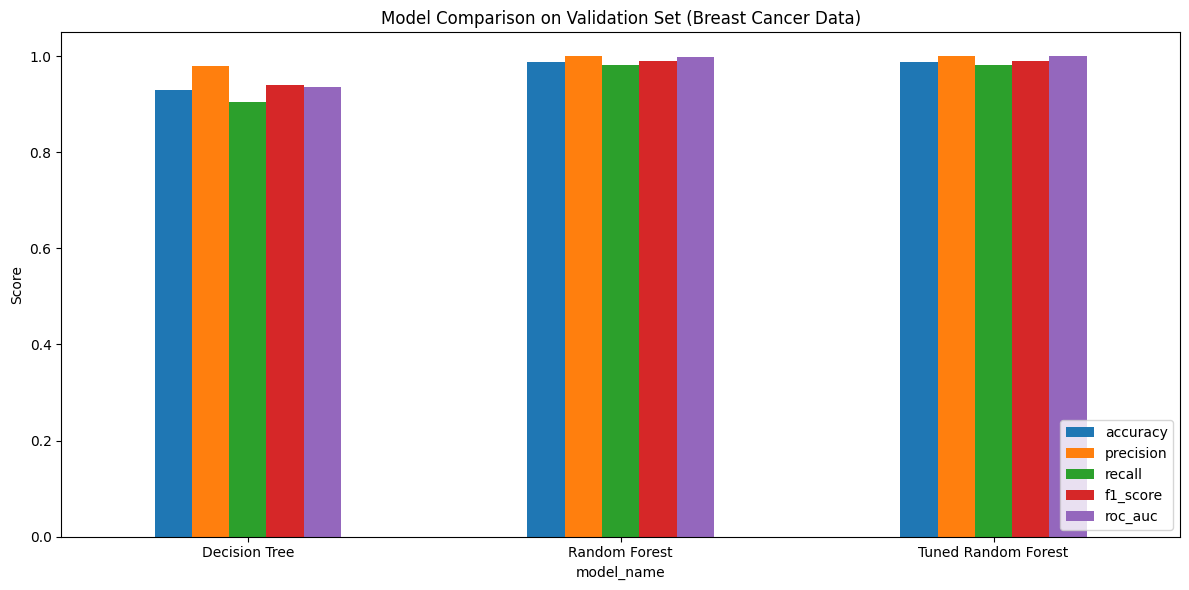

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Helper function for evaluation (ensures consistent metric formatting)
def evaluate_model(model_name, y_true, y_pred, y_proba):
    return {
        "model_name": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1_score": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba)
    }

# 2. Load the Breast Cancer Dataset (Guaranteed 30 Features)
data = load_breast_cancer()
# Keep data as a DataFrame so feature names are consistently preserved
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(f"Initial Dataset Shape: {X.shape} (Must be 30 features)")

# 3. Clean 3-Way Splitting (Train: 70%, Validation: 15%, Test: 15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# 4. Train and Evaluate Base Decision Tree
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
tree_val_pred = tree_model.predict(X_val)
tree_val_proba = tree_model.predict_proba(X_val)[:, 1]
tree_results = evaluate_model("Decision Tree", y_val, tree_val_pred, tree_val_proba)

# 5. Train and Evaluate Base Random Forest
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_val_pred = rf_model.predict(X_val)
rf_val_proba = rf_model.predict_proba(X_val)[:, 1]
rf_results = evaluate_model("Random Forest", y_val, rf_val_pred, rf_val_proba)

# 6. Hyperparameter Tuning using Grid Search (Fixed Valid Parameters)
param_grid = {
    'n_estimators':[100,200,300],
    'max_depth': [None, 10, 20],
    'max_features': ['sqrt', 'log2', None]  # Removed 'auto' to prevent FitFailedWarning
}

# Run Grid Search specifically using our 30-feature X_train
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

# 7. Extract and Evaluate the Best Tuned Model on Validation Set
best_rf = grid_search.best_estimator_
tuned_val_pred = best_rf.predict(X_val)         # Fixed data alignment (Using X_val)
tuned_val_proba = best_rf.predict_proba(X_val)[:, 1]
tuned_results = evaluate_model("Tuned Random Forest", y_val, tuned_val_pred, tuned_val_proba)

# 8. Create Comparison Table and Print Results
comparison = pd.DataFrame([tree_results, rf_results, tuned_results]).round(4)
print("\nDecision Tree vs Random Forest vs Tuned Random Forest (Validation Set)")
print(comparison.to_string(index=False))

# 9. Plot the performance metrics bar chart safely using the lowercase column index
comparison.set_index("model_name").plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Model Comparison on Validation Set (Breast Cancer Data)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


step 14: feature importance with impurity based feature

In [46]:
importance_df=pd.DataFrame({
    "feature":X_train.columns,
    "importance":best_rf.feature_importances_}).sort_values("importance",ascending=False)

print(importance_df.head(10).round(4).to_string(index=False))

             feature  importance
     worst perimeter      0.1216
          worst area      0.1190
worst concave points      0.1049
 mean concave points      0.0804
        worst radius      0.0784
      mean perimeter      0.0676
         mean radius      0.0639
           mean area      0.0561
      mean concavity      0.0544
     worst concavity      0.0383


step15: permutation based feature importance

In [48]:
parm_result=permutation_importance(best_rf,X_val,y_val,n_repeats=10,random_state=42,n_jobs=-1)

permutation_df=pd.DataFrame({
    "feature":X_train.columns,
    "importance":parm_result.importances_mean
}).sort_values("importance",ascending=False)

print(permutation_df.head(10).round(4).to_string(index=False))

             feature  importance
       worst texture      0.0118
        mean texture      0.0106
worst concave points      0.0071
     perimeter error      0.0059
        worst radius      0.0059
          worst area      0.0059
 mean concave points      0.0047
    worst smoothness      0.0047
   compactness error      0.0035
           mean area      0.0035


step 15: confusion matrix for breast cancer dataset

In [49]:
cm=confusion_matrix(y_val,tuned_val_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_val,tuned_val_pred))


Confusion Matrix:
[[32  0]
 [ 1 52]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        32
           1       1.00      0.98      0.99        53

    accuracy                           0.99        85
   macro avg       0.98      0.99      0.99        85
weighted avg       0.99      0.99      0.99        85



step 16: final test evaluartion

In [50]:
final_test_pred=best_rf.predict(X_test)
final_test_proba=best_rf.predict_proba(X_test)[:,1]

final_test_results=evaluate_model("Final Test",y_test,final_test_pred,final_test_proba)

print(pd.DataFrame([final_test_results]).round(4).to_string(index=False))

model_name  accuracy  precision  recall  f1_score  roc_auc
Final Test     0.907     0.8966   0.963    0.9286   0.9821


In [52]:
comparison.to_csv(
    "day12_model_comparison.csv",
    index=False
)

pd.DataFrame(
    grid_search.cv_results_
).to_csv(
    "day12_hyperparameter_results.csv",
    index=False
)

importance_df.to_csv(
    "day12_impurity_importance.csv",
    index=False
)

permutation_df.to_csv(
    "day12_permutation_importance.csv",
    index=False
)

# wrong_predictions.to_csv(
#     "day12_error_analysis.csv",
#     index=True
# )

pd.DataFrame(
    [final_test_results]
).to_csv(
    "day12_final_test_results.csv",
    index=False
)

print("All Day 12 result files saved successfully!")

All Day 12 result files saved successfully!


## Final Model Evaluation — Interpretation

- **Accuracy (90.7%):** The model correctly classified approximately 91% of the test samples.
- **Precision (89.66%):** Of all samples predicted as good quality, approximately 90% were actually good quality.
- **Recall (96.3%):** The model identified most of the actual good-quality samples.
- **F1-score (92.86%):** The model achieved a strong balance between precision and recall.
- **ROC-AUC (98.21%):** The model demonstrated excellent ability to distinguish between the two quality classes.
- **Overall conclusion:** The model shows strong test-set performance, with particularly high recall and ROC-AUC. Precision indicates there is still room to reduce false-positive predictions.

In [55]:
from google.colab import files
import os
import zipfile

result_files = [
    "day12_model_comparison.csv",
    "day12_hyperparameter_results.csv",
    "day12_impurity_importance.csv",
    "day12_permutation_importance.csv",
    "day12_error_analysis.csv",
    "day12_final_test_results.csv"
]

with zipfile.ZipFile(
    "day12_results.zip",
    "w"
) as zip_file:
    for filename in result_files:
        if os.path.exists(filename):
            zip_file.write(filename)

files.download("day12_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>